# 03 – Feature Engineering

Aus den bereinigten Kursen entstehen ausschließlich vergangenheitsbasierte Modellmerkmale. Alle Rolling Windows, Renditen und Targets werden getrennt je Ticker berechnet, damit keine Aktie Informationen einer anderen Reihe übernimmt.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.feature_engineering import FEATURE_COLUMNS, calculate_features, load_processed_prices

pd.set_option('display.max_columns', 20)
plt.style.use('seaborn-v0_8-whitegrid')

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\sheo1\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


## Feature-Abdeckung

Rolling Features benötigen eine Anlaufphase. Beispielsweise steht der 30-Tage-Durchschnitt erst ab dem 30. Handelstag eines Tickers zur Verfügung.

In [2]:
prices = load_processed_prices()
features = calculate_features(prices)
coverage = (features[FEATURE_COLUMNS].notna().mean().mul(100).round(2)
            .rename('coverage_percent').to_frame())
coverage

,coverage_percent
daily_return,99.92
moving_average_7,99.52
moving_average_30,97.70
volatility_30,97.62
momentum_7,99.45
volume_change,99.90


## Beispiel: Trendmerkmale für AAPL

Der 7-Tage-Durchschnitt reagiert schneller auf Kursänderungen, während der 30-Tage-Durchschnitt den längerfristigen Trend glättet.

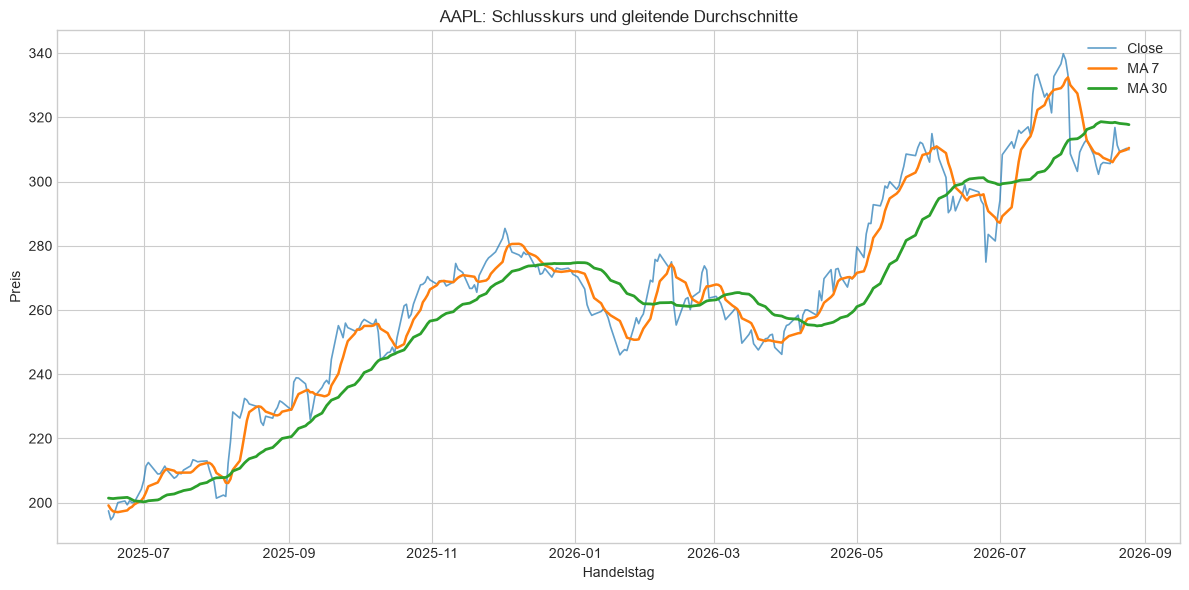

In [3]:
aapl_features = features.loc[features['ticker'] == 'AAPL'].tail(300)
aapl_prices = prices.loc[prices['ticker'] == 'AAPL', ['trade_date', 'close_price']]
aapl = aapl_features.merge(aapl_prices, on=['trade_date'], how='left')

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(aapl['trade_date'], aapl['close_price'], label='Close', linewidth=1.2, alpha=0.7)
ax.plot(aapl['trade_date'], aapl['moving_average_7'], label='MA 7', linewidth=1.8)
ax.plot(aapl['trade_date'], aapl['moving_average_30'], label='MA 30', linewidth=2.0)
ax.set(title='AAPL: Schlusskurs und gleitende Durchschnitte', xlabel='Handelstag', ylabel='Preis')
ax.legend()
plt.tight_layout()
plt.show()

## Zusammenhang der Modellmerkmale

Die Korrelationsmatrix macht redundante Merkmale sichtbar. Stark korrelierte gleitende Durchschnitte sind erwartbar, weil beide auf demselben Kursniveau beruhen.

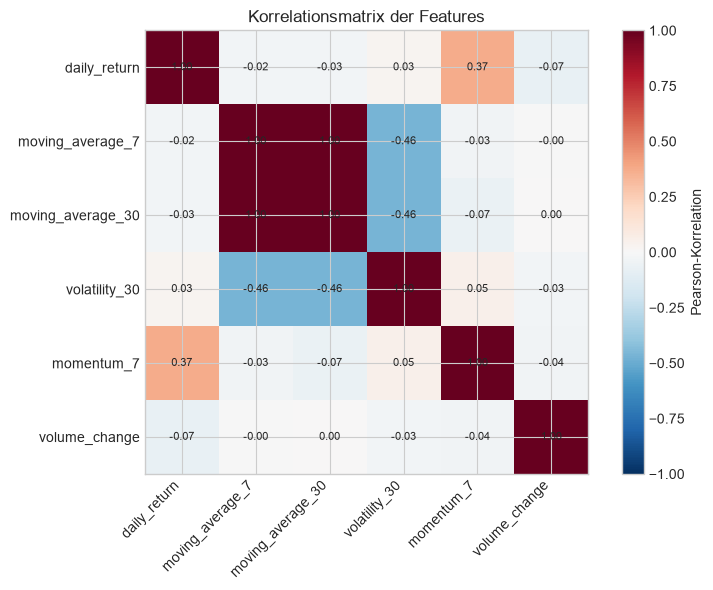

In [4]:
correlation = features[FEATURE_COLUMNS].corr()
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlation, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURE_COLUMNS)), FEATURE_COLUMNS, rotation=45, ha='right')
ax.set_yticks(range(len(FEATURE_COLUMNS)), FEATURE_COLUMNS)
for row in range(len(FEATURE_COLUMNS)):
    for column in range(len(FEATURE_COLUMNS)):
        ax.text(column, row, f'{correlation.iloc[row, column]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=ax, label='Pearson-Korrelation')
ax.set_title('Korrelationsmatrix der Features')
plt.tight_layout()
plt.show()

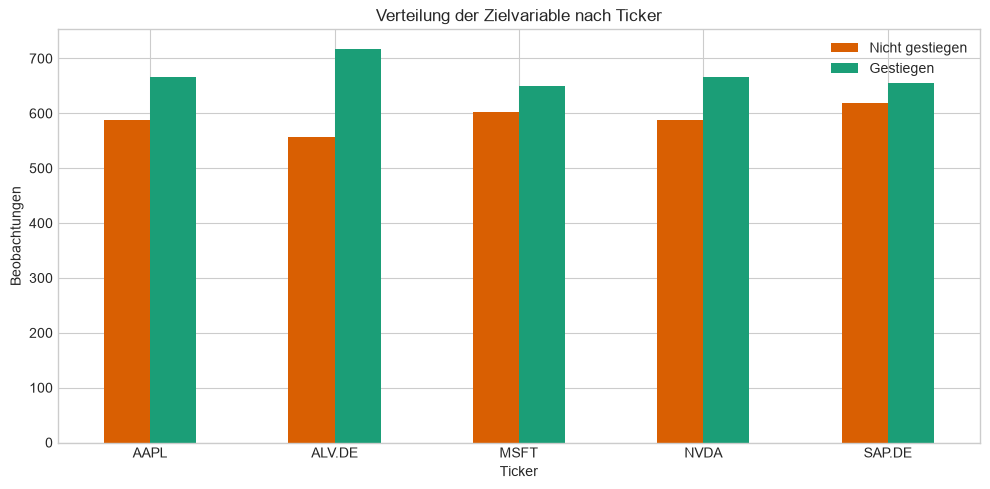

,Nicht gestiegen,Gestiegen
ticker,,
AAPL,587,666
ALV.DE,557,717
MSFT,603,650
NVDA,587,666
SAP.DE,618,656


In [5]:
target_balance = (features.dropna(subset=['target_next_day_up'])
                  .groupby(['ticker', 'target_next_day_up']).size()
                  .unstack(fill_value=0))
target_balance.columns = ['Nicht gestiegen', 'Gestiegen']
ax = target_balance.plot(kind='bar', figsize=(10, 5), color=['#d95f02', '#1b9e77'])
ax.set(title='Verteilung der Zielvariable nach Ticker', xlabel='Ticker', ylabel='Beobachtungen')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
target_balance

## Ergebnis

Die Feature-Schicht stellt technische Trend-, Momentum-, Volatilitäts- und Volumenmerkmale sowie die Kursrichtung des nächsten Handelstags bereit. Die letzte Zeile jedes Tickers besitzt bewusst kein Target, weil der Folgetag unbekannt ist.